# ML Lab Assignment 2
# Taneesha Badhe, Panel C, 1032232190

In [1]:
#IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.datasets import load_iris 
from sklearn.model_selection import train_test_split # data is split into training set and testing set
from sklearn.neighbors import KNeighborsClassifier # this algo classifies based on nearest points
from sklearn.naive_bayes import GaussianNB # this algo classifies using probability and gaussian distribution
from sklearn.preprocessing import StandardScaler, MinMaxScaler # important for knn # standard works on mean and std, minmax works between values 0 to 1
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [3]:
# LOAD IRIS DATASET
iris = load_iris()

X = iris.data # input features
y = iris.target # output label

print("Feature Names:", iris.feature_names)
print("Target Names:", iris.target_names)

Feature Names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target Names: ['setosa' 'versicolor' 'virginica']


In [4]:
# TRAIN TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42 # same split in every run
)

In [5]:
# KNN CLASSIFICATION K=5

knn = KNeighborsClassifier(n_neighbors=5) # knn model creation
knn.fit(X_train, y_train)  # learn and store training data

y_pred_knn = knn.predict(X_test) # store predictions

# compare between actual and predicted
print("Accuracy (K=5):", accuracy_score(y_test, y_pred_knn)) 
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_knn))
print("Classification Report:\n", classification_report(y_test, y_pred_knn))

Accuracy (K=5): 1.0
Confusion Matrix:
 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [6]:
#ACCURACY FOR RANGE OF K VALUES

k_values = range(1, 21) # test from 1 to 20
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k) # create model for each k
    model.fit(X_train, y_train)  # train and predict
    y_pred = model.predict(X_test) 
    acc = accuracy_score(y_test, y_pred) 
    accuracies.append(acc)
    print("K =", k, "Accuracy =", acc)  #store and print accuracy

K = 1 Accuracy = 1.0
K = 2 Accuracy = 1.0
K = 3 Accuracy = 1.0
K = 4 Accuracy = 1.0
K = 5 Accuracy = 1.0
K = 6 Accuracy = 1.0
K = 7 Accuracy = 0.9666666666666667
K = 8 Accuracy = 1.0
K = 9 Accuracy = 1.0
K = 10 Accuracy = 1.0
K = 11 Accuracy = 1.0
K = 12 Accuracy = 1.0
K = 13 Accuracy = 1.0
K = 14 Accuracy = 1.0
K = 15 Accuracy = 1.0
K = 16 Accuracy = 1.0
K = 17 Accuracy = 1.0
K = 18 Accuracy = 1.0
K = 19 Accuracy = 1.0
K = 20 Accuracy = 1.0


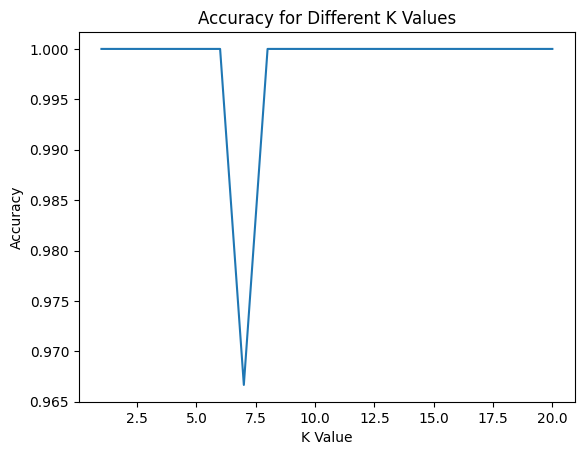

In [7]:
# PLOT FOR ABOVE CELL

plt.plot(k_values, accuracies) # k vs accuracy graph
plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("Accuracy for Different K Values")
plt.show()

In [8]:
#KNN WITH STANDARD SCALER

scaler_std = StandardScaler() # create scaling object

X_train_std = scaler_std.fit_transform(X_train) #calculate mean and std & transform the data (z = (x − mean) / std)
X_test_std = scaler_std.transform(X_test) # fit not used here because we need training data statistics

knn_std = KNeighborsClassifier(n_neighbors=5)
knn_std.fit(X_train_std, y_train)

y_pred_std = knn_std.predict(X_test_std)

print("Accuracy with StandardScaler:",
      accuracy_score(y_test, y_pred_std))

Accuracy with StandardScaler: 1.0


In [9]:
#KNN WITH MINMAX SCALER

scaler_mm = MinMaxScaler() # Formula: (x − min) / (max − min)

# process is same as above

X_train_mm = scaler_mm.fit_transform(X_train)
X_test_mm = scaler_mm.transform(X_test)

knn_mm = KNeighborsClassifier(n_neighbors=5)
knn_mm.fit(X_train_mm, y_train)

y_pred_mm = knn_mm.predict(X_test_mm)

print("Accuracy with MinMaxScaler:",
      accuracy_score(y_test, y_pred_mm))

Accuracy with MinMaxScaler: 1.0


In [10]:
#GAUSSIAN NAIVE BAYES

gnb = GaussianNB() # create gaussian model
gnb.fit(X_train, y_train) # learn means and variances

y_pred_gnb = gnb.predict(X_test) # predict using probability

# calculation same as knn

print("Gaussian NB Accuracy:",
      accuracy_score(y_test, y_pred_gnb))

print("Confusion Matrix:\n",
      confusion_matrix(y_test, y_pred_gnb))

print("Classification Report:\n",
      classification_report(y_test, y_pred_gnb))

Gaussian NB Accuracy: 1.0
Confusion Matrix:
 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [11]:
# ALL ACCURACY COMPARISON

print("Final Comparison:")
print("KNN (K=5):", accuracy_score(y_test, y_pred_knn))
print("KNN + StandardScaler:",
      accuracy_score(y_test, y_pred_std))
print("KNN + MinMaxScaler:",
      accuracy_score(y_test, y_pred_mm))
print("Gaussian NB:",
      accuracy_score(y_test, y_pred_gnb))

Final Comparison:
KNN (K=5): 1.0
KNN + StandardScaler: 1.0
KNN + MinMaxScaler: 1.0
Gaussian NB: 1.0
